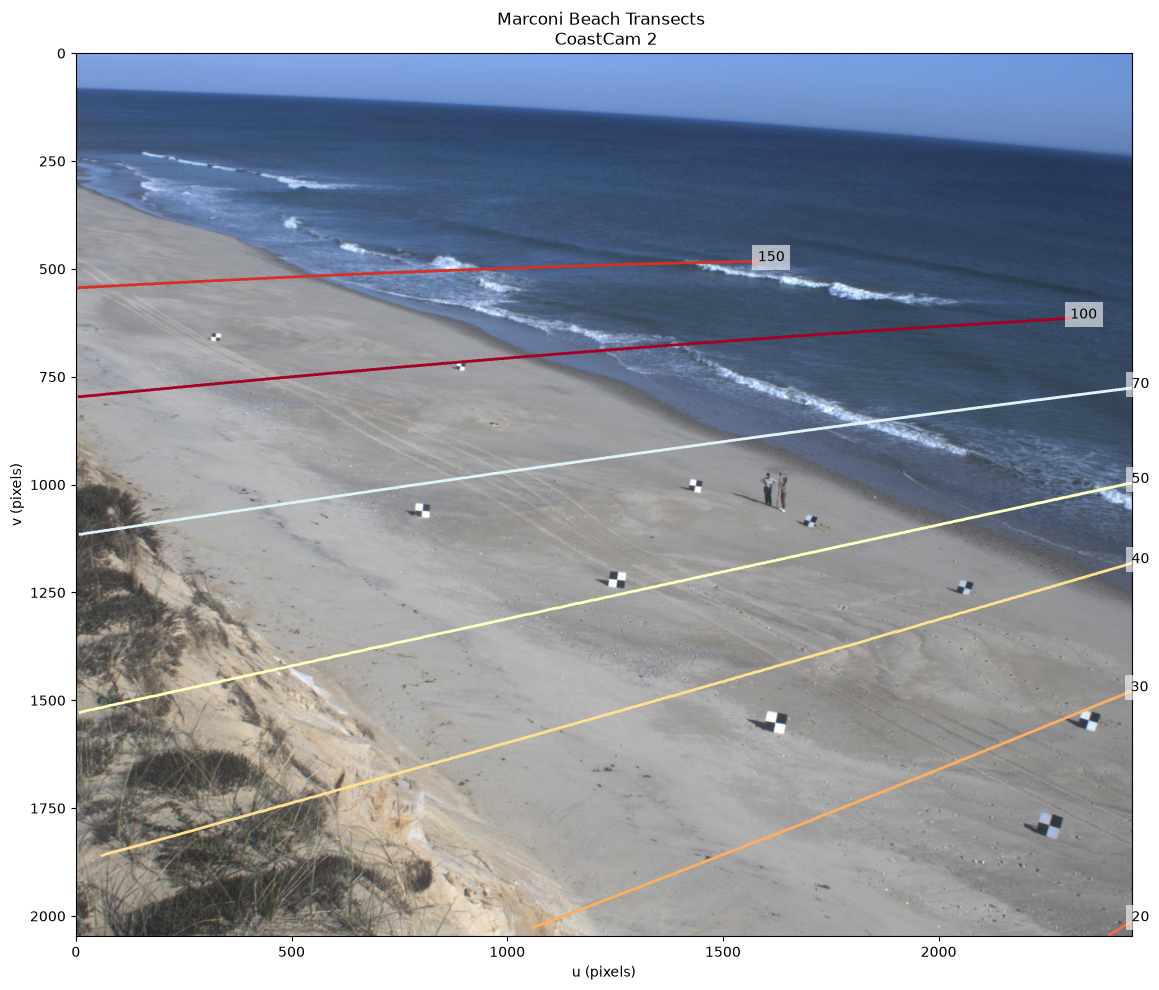

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import yaml
from PIL import Image

# ------------------------------------------------------------------
# USER INPUTS
# ------------------------------------------------------------------
image_file = "E:/cvolpano/shorescan_processing/CACO03_c2_20241023_GCP_image_raw.jpg"
# transect_file = "DATA/DATA/CACO03_c2_timestack_20240920.pix"



with open("E:/cvolpano/shorescan_processing/CACO04_c2_20250123_output.yaml", "r") as f:
    data = yaml.safe_load(f)\

dfs = {}

for transect, values in data.items():

    cols = {}

    for key, value in values.items():

        # Handle empty fields (e.g., V:)
        if value is None or value == "":
            continue

        # Convert comma-separated string to numeric array
        cols[key] = np.array(
            [float(x) for x in str(value).split(",") if x.strip()]
        )

    dfs[transect] = pd.DataFrame(cols)
   
# ------------------------------------------------------------------
# LOAD IMAGE
# ------------------------------------------------------------------
img = np.array(Image.open(image_file))


# ------------------------------------------------------------------
# PLOT
# ------------------------------------------------------------------
n_colors = len(transect)

# Choose a colormap (e.g., 'viridis', 'plasma', 'tab20', etc.)
cmap = mpl.colormaps['RdYlBu'].resampled(n_colors)

fig, ax = plt.subplots(figsize=(12, 10))

ax.imshow(img)

count =0
for transect, values in data.items():

     # Handle empty fields (e.g., V:)
    U = np.array([float(x) for x in values['U'].split(',') if x.strip()])
    V = np.array([float(x) for x in values['V'].split(',') if x.strip()])

    if len(U) == 0 or len(V) == 0:
        print(f"Skipping {transect}: empty U or V")
        continue

    ax.plot(U, V, '-', lw=2,c=cmap(count))
    # Label at first point
    # Label at first point
    label = transect.split('_')[-1]
    
    ax.text(
        U[-1],
        V[-1],
        label,
        fontsize=10,
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='none')
    )
    count=count+1
ax.set_aspect('equal')
ax.set_title(f"Marconi Beach Transects \n CoastCam 2")
ax.set_xlabel("u (pixels)")
ax.set_ylabel("v (pixels)")

plt.tight_layout()
plt.savefig('E:/cvolpano/shorescan_processing/results/output_plots/Transects_c2_10232024.png')
plt.show()